# NESG: dataset validation and evaluation design

Can the strict NESG cohort support heterogeneous ESM analysis and controlled within-family comparisons?

This notebook audits experimental labels, diversity and evaluation design using existing Pfam 37.0 and MMseqs2 results. It trains no models and leaves the UESolDS independent test untouched.

**Reruns:** Sections 1–4 display frozen aggregate tables after `results/test_lock.json` is created; Sections 5–6 analyze training/validation records. Keep the existing lock and splits.

**Subsequent exposure:** Test labels were later inspected by family at the user's request. See [TEST_LABEL_EXPOSURE.md](TEST_LABEL_EXPOSURE.md). The saved lock status describes access controls, not an uninspected holdout. That report must not guide cohort, split, model-selection or hypothesis changes.

In [1]:
from pathlib import Path
import sys
import json
import importlib.metadata
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

HERE = Path.cwd()
ROOT = HERE if (HERE / "analysis_helpers.py").exists() else HERE / "nesg_primary"
ROOT = ROOT.resolve()
REPO = ROOT.parent
sys.path.insert(0, str(ROOT))
from analysis_helpers import (  # noqa: E402 — requires the repository path above
    AA,
    COLORS,
    LABELS,
    read,
    save,
    seqhash,
    md,
    show,
    prevalence,
    support,
    component_ids,
    initialize_inputs,
    freeze,
    verify_frozen_snapshot,
    ReadGuard,
)

RESULTS = ROOT / "results"
FIGURES = ROOT / "figures"
RESULTS.mkdir(exist_ok=True)
FIGURES.mkdir(exist_ok=True)
LOCKED = (RESULTS / "test_lock.json").exists()
if LOCKED:
    lock = verify_frozen_snapshot(RESULTS)
    print("LOCKED rerun: initial aggregate snapshots + development-only analysis.")
else:
    print("Initial audit: fixed policy, then one-time test lock.")
guard = ReadGuard(REPO, ROOT, LOCKED)
plt.rcParams.update(
    {
        "font.family": "DejaVu Sans",
        "font.size": 10,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "svg.fonttype": "none",
    }
)
pd.set_option("display.max_rows", 30)
pd.set_option("display.max_colwidth", 65)

LOCKED rerun: initial aggregate snapshots + development-only analysis.


## 1. Dataset overview and experimental phenotype

The [Price et al. study](https://pmc.ncbi.nlm.nih.gov/articles/PMC3372292/) used E. coli BL21λ(DE3), pET/His-tag constructs, pMGK and overnight growth at 18°C. Gel-based **E** scores expression; **S** scores soluble recovery after centrifugation. S=0 means no recovered soluble protein; S=5 means approximately complete recovery. These are ordinal scores. S was not recorded for E=0 in the original study.

The study primarily used maximum scores when clones disagreed and considered averages in sensitivity analyses. This does not explain the fractional scores in the recovered mirror. The methods are study-level evidence; record-level assay metadata are unavailable.

The established cohort includes singleton-sequence records with **E ∈ {4,5}**, labeled soluble for **S ∈ {4,5}** and insoluble for **S=0**. All repeated-sequence observations, including agreeing repeats, remain in the exclusion ledger.

In [2]:
if not LOCKED:
    raw, netsolp, cohort, domains, edges = initialize_inputs(REPO, RESULTS)
    unique = raw.loc[~raw.repeated_sequence]
    reasons = (
        raw.exclusion_reason.value_counts().rename_axis("reason").reset_index(name="N")
    )
    save(reasons, RESULTS / "selection_reasons.tsv")
    score_table = pd.crosstab(raw.exp, raw.sol).reindex(columns=range(6), fill_value=0)
    save(
        score_table.rename_axis("E").reset_index(), RESULTS / "raw_E_S_contingency.tsv"
    )
    duplicate_summary = pd.DataFrame(
        [
            ["Raw records", len(raw)],
            ["Distinct sequence hashes", raw.sha256.nunique()],
            ["Repeated-sequence records", int(raw.repeated_sequence.sum())],
            [
                "Repeated sequence groups",
                raw.loc[raw.repeated_sequence, "sha256"].nunique(),
            ],
            ["Contradictory-score records", int(raw.conflicting_scores.sum())],
            [
                "Contradictory sequence groups",
                raw.loc[raw.conflicting_scores, "sha256"].nunique(),
            ],
            ["Noninteger E records", int((raw.exp % 1 != 0).sum())],
            ["E=0, S>0 records", int(((raw.exp == 0) & (raw.sol > 0)).sum())],
        ],
        columns=["finding", "N"],
    )
    save(duplicate_summary, RESULTS / "duplicate_anomaly_counts.tsv")
    reconciliation = pd.DataFrame(
        [
            [
                "Historical Price publication",
                9644,
                np.nan,
                np.nan,
                "Exact historical membership unavailable",
            ],
            [
                "Recovered NESG archive",
                len(raw),
                np.nan,
                np.nan,
                "Score-bearing records; no blanket binary labels",
            ],
            [
                "Singleton-sequence reconstruction",
                len(unique),
                np.nan,
                np.nan,
                "Drop all 431 records belonging to repeated sequences",
            ],
            [
                "Strict primary cohort",
                len(cohort),
                int(cohort.label.sum()),
                int((cohort.label == 0).sum()),
                "Same 3,762 records as completed audit",
            ],
            [
                "NetSolP NESG release",
                len(netsolp),
                int(pd.to_numeric(netsolp.label).sum()),
                int((pd.to_numeric(netsolp.label) == 0).sum()),
                "Derivative with additional PSI homology filtering",
            ],
        ],
        columns=["version", "N", "soluble", "insoluble", "interpretation"],
    )
    save(reconciliation, RESULTS / "reconciliation.tsv")
    exceptions = netsolp.loc[~netsolp.exp.isin([4, 5]), ["sid", "exp", "sol", "label"]]
    save(exceptions, RESULTS / "netsolp_rule_exceptions.tsv")
    # A sensitivity inventory, not another primary cohort.
    consistent = (
        raw.loc[~raw.conflicting_scores].sort_values("sid").drop_duplicates("sha256")
    )
    sensitivity = []
    for name, pool in [
        ("singleton", unique),
        ("one_per_consistent_sequence", consistent),
    ]:
        for emin, smin in [(4, 4), (3, 4), (4, 3)]:
            q = pool[
                pool.exp.isin(range(emin, 6))
                & pool.sol.isin([0] + list(range(smin, 6)))
            ]
            sensitivity.append(
                dict(
                    policy=name,
                    E_min=emin,
                    S_positive_min=smin,
                    N=len(q),
                    soluble=int((q.sol >= smin).sum()),
                    insoluble=int((q.sol == 0).sum()),
                )
            )
    save(pd.DataFrame(sensitivity), RESULTS / "score_policy_sensitivity.tsv")
    # Identifier stems are candidate construct links, not verified gene or batch identities.
    raw["candidate_stem"] = raw.sid.str.replace(r"(?<=\d)[A-Z]$", "", regex=True)
    stem = raw.groupby("candidate_stem").agg(
        records=("sid", "size"),
        sequences=("sha256", "nunique"),
        length_min=("length", "min"),
        length_max=("length", "max"),
        E_values=("exp", "nunique"),
        S_values=("sol", "nunique"),
    )
    stem = stem[stem.sequences > 1].reset_index()
    save(stem, RESULTS / "candidate_construct_stems.tsv")
    e90 = edges[
        (edges.identity >= 0.90)
        & edges["query"].isin(raw.sha256)
        & edges.target.isin(raw.sha256)
        & (edges["query"] < edges.target)
    ]
    save(
        pd.DataFrame(
            [
                {
                    "candidate_identifier_stems_with_different_sequences": len(stem),
                    "stems_with_length_variation": int(
                        (stem.length_min != stem.length_max).sum()
                    ),
                    "nonidentical_sequence_pairs_identity90_coverage80": len(e90),
                }
            ]
        ),
        RESULTS / "construct_variation_summary.tsv",
    )

display(read(RESULTS / "reconciliation.tsv"))
display(read(RESULTS / "duplicate_anomaly_counts.tsv"))
display(read(RESULTS / "netsolp_rule_exceptions.tsv"))

,version,N,soluble,insoluble,interpretation
0,Historical Price publication,9644,,,Exact historical membership unavailable
1,Recovered NESG archive,9703,,,Score-bearing records; no blanket binary labels
2,Singleton-sequence reconstruction,9272,,,Drop all 431 records belonging to repeated sequences
3,Strict primary cohort,3762,2614.0,1148.0,"Same 3,762 records as completed audit"
4,NetSolP NESG release,1323,842.0,481.0,Derivative with additional PSI homology filtering


,finding,N
0,Raw records,9703
1,Distinct sequence hashes,9478
2,Repeated-sequence records,431
3,Repeated sequence groups,206
4,Contradictory-score records,316
5,Contradictory sequence groups,150
6,Noninteger E records,9
7,"E=0, S>0 records",59


,sid,exp,sol,label
0,MAR120,4.5,0.0,0.0
1,MAR123,3.5,5.0,1.0
2,PFR1,3.5,0.0,0.0


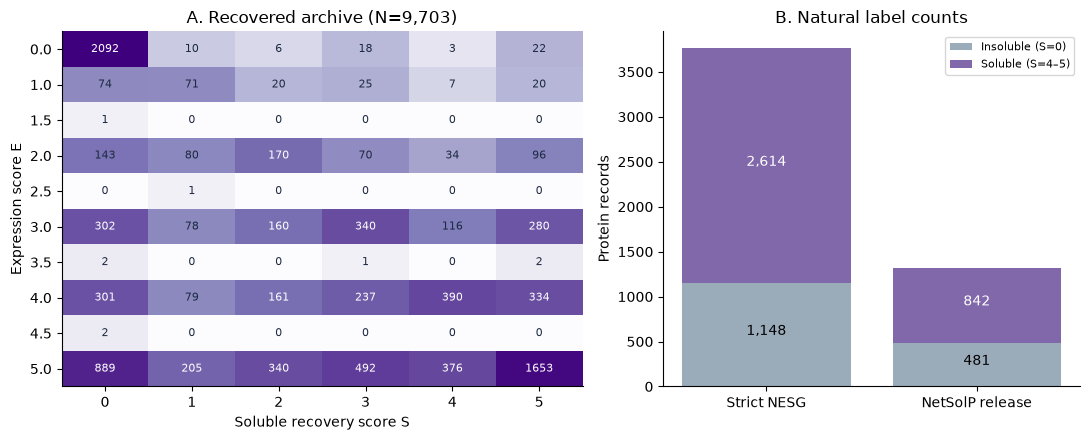

In [3]:
scores = read(RESULTS / "raw_E_S_contingency.tsv").set_index("E")
rec = read(RESULTS / "reconciliation.tsv")
fig, axs = plt.subplots(
    1, 2, figsize=(11, 4.5), gridspec_kw={"width_ratios": [1.25, 1]}
)
axs[0].imshow(np.log1p(scores.to_numpy(dtype=float)), cmap="Purples", aspect="auto")
axs[0].set(
    xticks=range(6),
    xticklabels=scores.columns,
    yticks=range(len(scores)),
    yticklabels=scores.index,
    xlabel="Soluble recovery score S",
    ylabel="Expression score E",
    title="A. Recovered archive (N=9,703)",
)
for i in range(len(scores)):
    for j in range(6):
        n = int(scores.iloc[i, j])
        axs[0].text(
            j,
            i,
            str(n),
            ha="center",
            va="center",
            fontsize=8,
            color="white" if n > 150 else "#1c2940",
        )
for x, version in enumerate(["Strict primary cohort", "NetSolP NESG release"]):
    r = rec[rec.version == version].iloc[0]
    n0 = int(float(r.insoluble))
    n1 = int(float(r.soluble))
    axs[1].bar(x, n0, color=COLORS[0], label=LABELS[0] if x == 0 else None)
    axs[1].bar(x, n1, bottom=n0, color=COLORS[1], label=LABELS[1] if x == 0 else None)
    axs[1].text(x, n0 / 2, f"{n0:,}", ha="center")
    axs[1].text(x, n0 + n1 / 2, f"{n1:,}", ha="center", color="white")
axs[1].set(
    xticks=[0, 1],
    xticklabels=["Strict NESG", "NetSolP release"],
    ylabel="Protein records",
    title="B. Natural label counts",
)
axs[1].legend(fontsize=8)
fig.tight_layout()
show(fig, "fig01_scores_and_labels", FIGURES)

**Figure 1.** Numeric S values for E=0 are preserved but cannot establish measured insolubility. Fractional E scores remain unrounded. NetSolP's three threshold exceptions are MAR120, MAR123 and PFR1. Its release derives from the same experiments. The historical 9,644-record membership remains unresolved; removing 59 arbitrary rows from the recovered archive would not recover it. Binary counts require an explicit score policy.

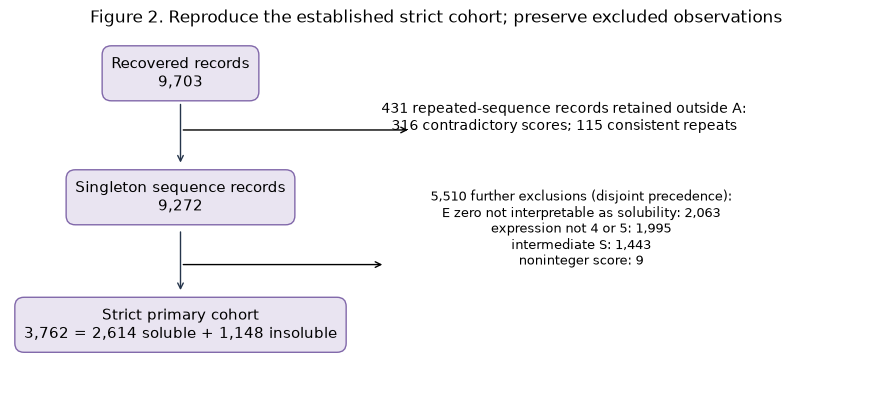

,policy,E_min,S_positive_min,N,soluble,insoluble
0,singleton,4,4,3762,2614,1148
1,singleton,3,4,4436,2992,1444
2,singleton,4,3,4458,3310,1148
3,one_per_consistent_sequence,4,4,3792,2638,1154
4,one_per_consistent_sequence,3,4,4467,3017,1450
5,one_per_consistent_sequence,4,3,4490,3336,1154


,candidate_identifier_stems_with_different_sequences,stems_with_length_variation,nonidentical_sequence_pairs_identity90_coverage80
0,437,437,1628


In [4]:
reasons = read(RESULTS / "selection_reasons.tsv").set_index("reason").N
fig, ax = plt.subplots(figsize=(11, 4.6))
ax.axis("off")
boxes = [
    (0.20, 0.88, "Recovered records\n9,703"),
    (0.20, 0.53, "Singleton sequence records\n9,272"),
    (0.20, 0.17, "Strict primary cohort\n3,762 = 2,614 soluble + 1,148 insoluble"),
]
for x, y, t in boxes:
    ax.text(
        x,
        y,
        t,
        ha="center",
        va="center",
        bbox=dict(boxstyle="round,pad=.6", fc="#e9e4f1", ec="#8168aa"),
        fontsize=11,
    )
for y1, y2 in [(0.80, 0.62), (0.44, 0.26)]:
    ax.annotate(
        "",
        xy=(0.20, y2),
        xytext=(0.20, y1),
        arrowprops={"arrowstyle": "->", "color": "#25354b"},
    )
ax.text(
    0.65,
    0.72,
    "431 repeated-sequence records retained outside A:\n316 contradictory scores; 115 consistent repeats",
    ha="center",
    fontsize=10,
)
ax.annotate("", xy=(0.47, 0.72), xytext=(0.20, 0.72), arrowprops={"arrowstyle": "->"})
remaining = reasons.drop(
    [
        "repeated_sequence_consistent_scores",
        "repeated_sequence_conflicting_scores",
        "eligible",
    ]
)
ax.text(
    0.67,
    0.34,
    "5,510 further exclusions (disjoint precedence):\n"
    + "\n".join(f"{k.replace('_', ' ')}: {int(v):,}" for k, v in remaining.items()),
    ha="center",
    fontsize=9,
)
ax.annotate("", xy=(0.44, 0.34), xytext=(0.20, 0.34), arrowprops={"arrowstyle": "->"})
ax.set_title(
    "Figure 2. Reproduce the established strict cohort; preserve excluded observations"
)
show(fig, "fig02_selection_flow", FIGURES)
display(read(RESULTS / "score_policy_sensitivity.tsv"))
display(read(RESULTS / "construct_variation_summary.tsv"))

**Figure 2.** Removing all repeated-sequence observations leaves 9,272 records. Retaining one representative from agreeing repeats would yield 3,792 strict proteins, 30 more than the frozen cohort. The ledger preserves every exclusion. Shared identifier stems and ≥90%-identity matches identify possible construct variants or related proteins; they do not verify construct, vector, organism, batch or assay identity.

## 2. Experimental validity and technical biases

The mirror provides IDs, sequences and E/S scores. Record-level vector, tag, batch, protocol and replicate outcomes are unavailable. Study-level methods cannot fill these fields. Terminal His-runs are sequence flags; their absence cannot rule out experimental tags omitted from distributed sequences. E=4 versus E=5 is the available recorded technical comparison.

,variable,verified_record_level_N,missing_N,evidence
0,vector,0,3762,unavailable in recovered archive
1,experimental_tag,0,3762,unavailable in recovered archive
2,batch,0,3762,unavailable in recovered archive
3,assay_protocol,0,3762,unavailable in recovered archive
4,replicate_outcomes,0,3762,unavailable in recovered archive
5,E_score,3762,0,recorded ordinal expression score
6,terminal_His_run_proxy,3762,0,sequence-derived only; not experimental metadata


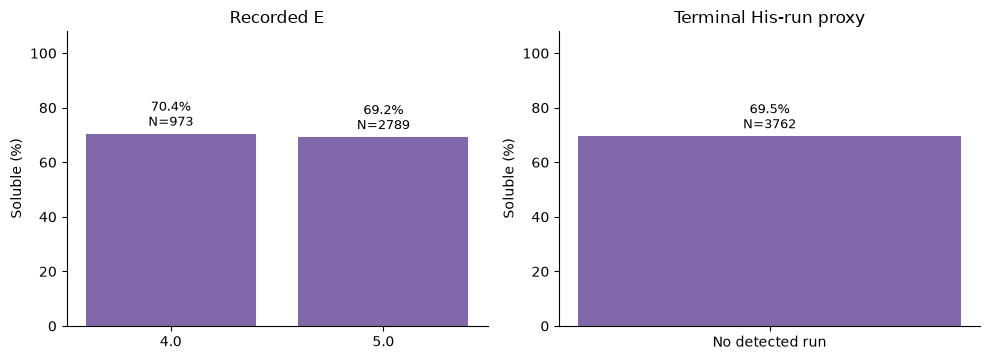

,exp,label,N,mean_length,mean_charge_proxy,mean_hydropathy
0,4.0,0,288,272.145833,-0.006365,-0.235926
1,4.0,1,685,236.677372,-0.003593,-0.362616
2,5.0,0,860,263.695349,-0.011475,-0.232683
3,5.0,1,1929,238.175220,-0.018603,-0.314231


In [5]:
if not LOCKED:
    technical = []
    for field in [
        "vector",
        "experimental_tag",
        "batch",
        "assay_protocol",
        "replicate_outcomes",
    ]:
        technical.append(
            dict(
                variable=field,
                verified_record_level_N=0,
                missing_N=len(cohort),
                evidence="unavailable in recovered archive",
            )
        )
    technical += [
        dict(
            variable="E_score",
            verified_record_level_N=len(cohort),
            missing_N=0,
            evidence="recorded ordinal expression score",
        ),
        dict(
            variable="terminal_His_run_proxy",
            verified_record_level_N=len(cohort),
            missing_N=0,
            evidence="sequence-derived only; not experimental metadata",
        ),
    ]
    save(pd.DataFrame(technical), RESULTS / "technical_metadata_availability.tsv")
    tech = pd.concat(
        [
            prevalence(cohort, "exp")
            .rename(columns={"exp": "category"})
            .assign(variable="Recorded E"),
            prevalence(cohort, "terminal_his")
            .rename(columns={"terminal_his": "category"})
            .assign(variable="Terminal His-run proxy"),
        ],
        ignore_index=True,
    )
    save(tech, RESULTS / "technical_label_associations.tsv")
    ef = (
        cohort.groupby(["exp", "label"])
        .agg(
            N=("label", "size"),
            mean_length=("length", "mean"),
            mean_charge_proxy=("charge_proxy", "mean"),
            mean_hydropathy=("hydropathy", "mean"),
        )
        .reset_index()
    )
    save(ef, RESULTS / "E_label_biochemistry.tsv")
display(read(RESULTS / "technical_metadata_availability.tsv"))
tech = read(RESULTS / "technical_label_associations.tsv")
fig, axs = plt.subplots(1, 2, figsize=(10, 3.7))
for ax, (variable, g) in zip(axs, tech.groupby("variable", sort=False)):
    ax.bar(np.arange(len(g)), g.percent_soluble, color="#8168aa")
    ax.set(
        ylim=(0, 108),
        xticks=np.arange(len(g)),
        xticklabels=(
            g.category.astype(str)
            if variable == "Recorded E"
            else [
                "No detected run" if float(v) == 0 else "Detected run"
                for v in g.category
            ]
        ),
        ylabel="Soluble (%)",
        title=variable,
    )
    for i, r in enumerate(g.itertuples()):
        ax.text(
            i,
            r.percent_soluble + 3,
            f"{r.percent_soluble:.1f}%\nN={r.N}",
            ha="center",
            fontsize=9,
        )
fig.tight_layout()
show(fig, "fig03_available_technical_variables", FIGURES)
display(read(RESULTS / "E_label_biochemistry.tsv"))

**Figure 3.** E-stratified proportions describe recovery among expressed proteins. Missing metadata prevents batch/vector adjustment and verification of assay equivalence. The constant terminal-His flag cannot support an association estimate. Joint E/label biochemical summaries check whether pooled patterns persist within expression strata; they do not establish causal effects.

## 3. Biological diversity and possible confounding

Use all GA-passing Pfam 37.0 hits with coordinates and overlap flags. Pfam families are domain models; clans group related families; MMseqs2 components describe sequence homology. Proteins without annotations remain in heterogeneous analysis A. These are descriptive cohort summaries.

,N,soluble,insoluble,annotated,families,clans,homology_groups,mixed_label_families,multifamily_proteins,nonstandard_sequences,beyond1022
0,3762,2614,1148,3510,1383,243,1820,390,1337,3,0


,label,N,annotated,percent
0,0,1148,1033,89.982578
1,1,2614,2477,94.758990


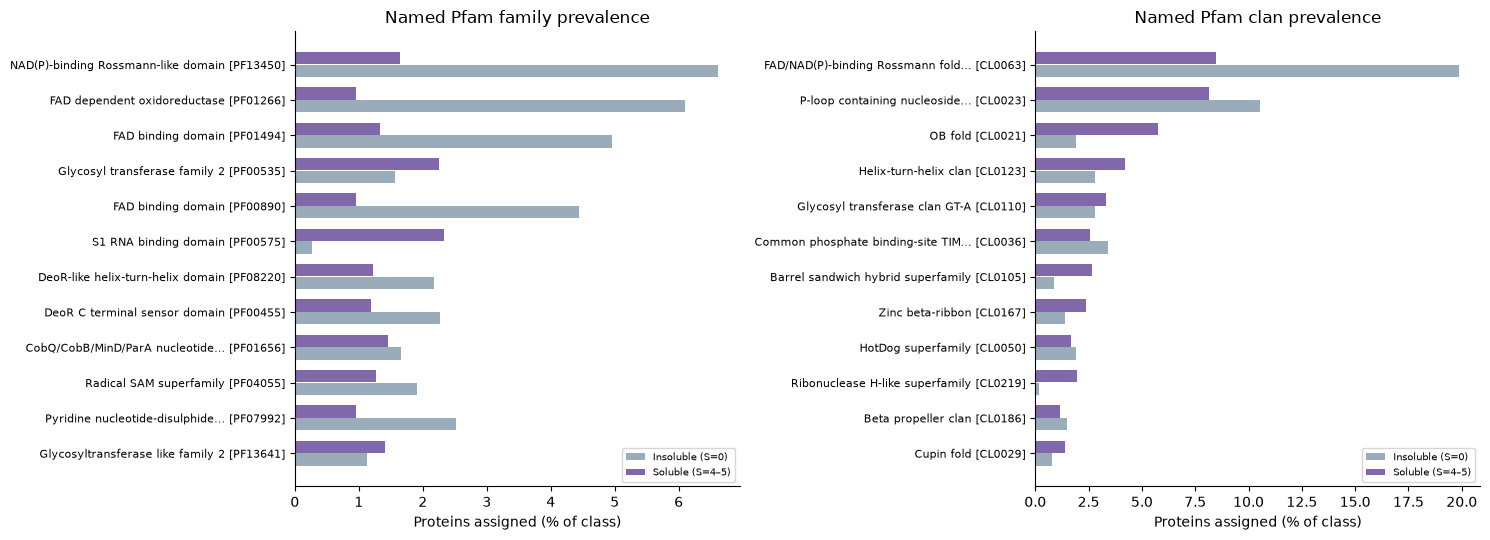

In [6]:
from textwrap import shorten

if not LOCKED:
    members = domains[
        ["sha256", "pfam", "clan", "family_name", "description"]
    ].drop_duplicates(["sha256", "pfam"])
    all_for_support = cohort.assign(split="all")
    fs, multi = support(all_for_support, members)
    save(fs, RESULTS / "initial_family_support.tsv")
    diversity = pd.DataFrame(
        [
            dict(
                N=len(cohort),
                soluble=int(cohort.label.sum()),
                insoluble=int((cohort.label == 0).sum()),
                annotated=cohort.sha256.isin(members.sha256).sum(),
                families=members.pfam.nunique(),
                clans=members.loc[members.clan != "", "clan"].nunique(),
                homology_groups=cohort.audit_cluster.nunique(),
                mixed_label_families=int(((fs.n0 > 0) & (fs.n1 > 0)).sum()),
                multifamily_proteins=int(
                    (multi.groupby("record_id").pfam.nunique() > 1).sum()
                ),
                nonstandard_sequences=int((cohort.nonstandard != "").sum()),
                beyond1022=int((cohort.length > 1022).sum()),
            )
        ]
    )
    save(diversity, RESULTS / "initial_diversity.tsv")
    hitcoverage = (
        cohort.groupby("label")
        .agg(N=("label", "size"), annotated=("pfam_annotated", "sum"))
        .reset_index()
    )
    hitcoverage["percent"] = 100 * hitcoverage.annotated / hitcoverage.N
    save(hitcoverage, RESULTS / "initial_annotation_coverage.tsv")
    clan_names = (
        read(
            REPO
            / "Violet969-PLM_Sol-3589a95/curation/presentation_assets/pfam37_clan_names.tsv"
        )
        .set_index("clan")
        .description
    )
    clan_members = domains[["sha256", "clan"]].query('clan!=""').drop_duplicates()
    clan_members["description"] = clan_members.clan.map(clan_names)
    composition = []
    for level, col, mem in [
        ("family", "pfam", members),
        ("clan", "clan", clan_members),
    ]:
        x = cohort[["record_id", "sha256", "label"]].merge(mem, on="sha256")
        rank = x.groupby(col).record_id.nunique().sort_values(ascending=False)
        for acc in rank.head(12).index:
            for lab in [0, 1]:
                z = x[(x[col] == acc) & (x.label == lab)]
                meta = x[x[col] == acc].iloc[0]
                den = int((cohort.label == lab).sum())
                composition.append(
                    dict(
                        level=level,
                        accession=acc,
                        name=meta.description,
                        label=lab,
                        N=z.record_id.nunique(),
                        percent=100 * z.record_id.nunique() / den,
                        rank=list(rank.index).index(acc) + 1,
                    )
                )
    save(
        pd.DataFrame(composition), RESULTS / "initial_named_biological_composition.tsv"
    )
    box = []
    means = []
    for label, g in cohort.groupby("label"):
        for feature in ["length", "charge_proxy", "hydropathy"]:
            v = pd.to_numeric(g[feature], errors="coerce").dropna()
            v = np.log10(v) if feature == "length" else v
            q = v.quantile([0.1, 0.25, 0.5, 0.75, 0.9])
            box.append(
                dict(
                    label=label,
                    feature=feature,
                    N=len(v),
                    q10=q.loc[0.1],
                    q25=q.loc[0.25],
                    median=q.loc[0.5],
                    q75=q.loc[0.75],
                    q90=q.loc[0.9],
                )
            )
        for aa in AA:
            means.append(
                dict(
                    label=label,
                    aa=aa,
                    mean_fraction=pd.to_numeric(
                        g["frac_" + aa], errors="coerce"
                    ).mean(),
                )
            )
    save(pd.DataFrame(box), RESULTS / "initial_biochemistry_box_summary.tsv")
    save(pd.DataFrame(means), RESULTS / "initial_composition_means.tsv")
display(read(RESULTS / "initial_diversity.tsv"))
display(read(RESULTS / "initial_annotation_coverage.tsv"))
comp = read(RESULTS / "initial_named_biological_composition.tsv")
fig, axs = plt.subplots(1, 2, figsize=(15, 5.5))

for ax, level in zip(axs, ["family", "clan"]):
    g = comp[comp.level == level]
    meta = g.drop_duplicates("accession").sort_values("rank")
    ids = meta.accession.tolist()
    y = np.arange(len(ids))
    for lab, offset in [(0, 0.18), (1, -0.18)]:
        values = (
            g[g.label == lab].set_index("accession").percent.reindex(ids, fill_value=0)
        )
        ax.barh(y + offset, values, 0.35, color=COLORS[lab], label=LABELS[lab])
    ax.set_yticks(
        y,
        [
            shorten(str(n), width=38, placeholder="…") + " [" + a + "]"
            for n, a in zip(meta.name, ids)
        ],
        fontsize=8,
    )
    ax.invert_yaxis()
    ax.set_title("Named Pfam " + level + " prevalence")
    ax.set_xlabel("Proteins assigned (% of class)")
    ax.legend(fontsize=7)
fig.tight_layout()
show(fig, "fig04_named_families_clans", FIGURES)

**Figure 4.** Categories are ranked by combined prevalence. Proteins count once per family or clan but may belong to several, so percentages can sum above 100%. Family–label associations, including Rossmann-like/NAD(P)-binding differences, are retained for studying indirect encoding. Section 5 assesses redundant support from overlapping Pfam models.

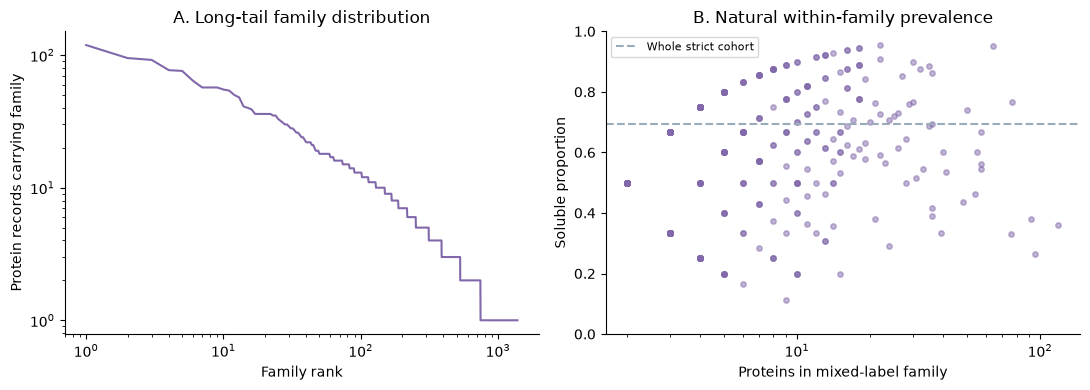

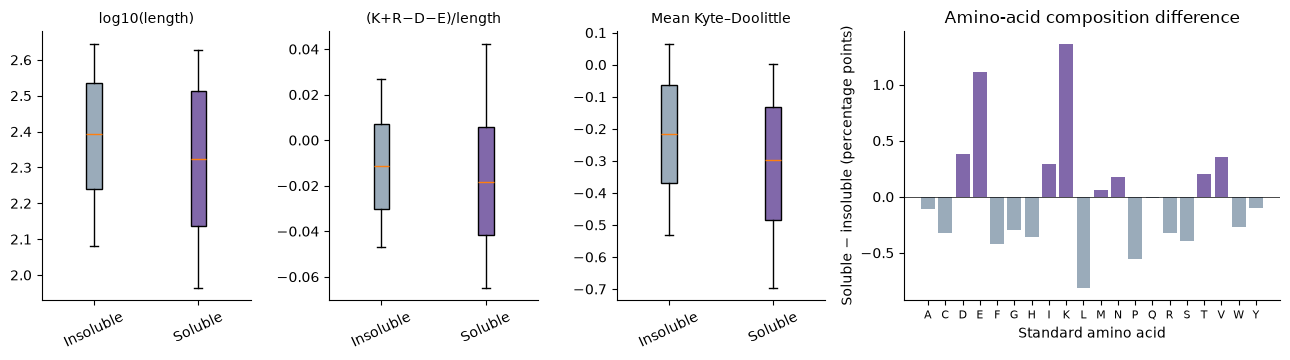

In [7]:
fs = read(RESULTS / "initial_family_support.tsv")
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
y = np.sort(fs.N.to_numpy())[::-1]
axs[0].loglog(np.arange(1, len(y) + 1), y, color="#8168aa")
axs[0].set(
    xlabel="Family rank",
    ylabel="Protein records carrying family",
    title="A. Long-tail family distribution",
)
mixed = fs[(fs.n0 > 0) & (fs.n1 > 0)]
axs[1].scatter(
    mixed.n0 + mixed.n1,
    mixed.n1 / (mixed.n0 + mixed.n1),
    s=15,
    alpha=0.5,
    color="#8168aa",
)
axs[1].set_xscale("log")
axs[1].set(
    xlabel="Proteins in mixed-label family",
    ylabel="Soluble proportion",
    ylim=(0, 1),
    title="B. Natural within-family prevalence",
)
axs[1].axhline(2614 / 3762, color="#9aabba", ls="--", label="Whole strict cohort")
axs[1].legend(fontsize=8)
fig.tight_layout()
show(fig, "fig05_family_size_and_labels", FIGURES)
box = read(RESULTS / "initial_biochemistry_box_summary.tsv")
fig, axs = plt.subplots(
    1, 4, figsize=(13, 3.7), gridspec_kw={"width_ratios": [1, 1, 1, 1.8]}
)
for ax, feature, title in zip(
    axs[:3],
    ["length", "charge_proxy", "hydropathy"],
    ["log10(length)", "(K+R−D−E)/length", "Mean Kyte–Doolittle"],
):
    g = box[box.feature == feature].sort_values("label")
    stats = [
        dict(
            label="Insoluble" if r.label == 0 else "Soluble",
            med=r.median,
            q1=r.q25,
            q3=r.q75,
            whislo=r.q10,
            whishi=r.q90,
            fliers=[],
        )
        for r in g.itertuples()
    ]
    artists = ax.bxp(stats, showfliers=False, patch_artist=True)
    for patch, lab in zip(artists["boxes"], g.label):
        patch.set_facecolor(COLORS[lab])
    ax.set_title(title, fontsize=10)
    ax.tick_params(axis="x", rotation=25)
means = (
    read(RESULTS / "initial_composition_means.tsv")
    .pivot(index="aa", columns="label", values="mean_fraction")
    .reindex(list(AA))
)
delta = 100 * (means[1] - means[0])
axs[3].bar(list(AA), delta, color=["#8168aa" if v >= 0 else "#9aabba" for v in delta])
axs[3].axhline(0, color="black", lw=0.5)
axs[3].set(
    title="Amino-acid composition difference",
    ylabel="Soluble − insoluble (percentage points)",
    xlabel="Standard amino acid",
)
axs[3].tick_params(axis="x", labelsize=8)
fig.tight_layout()
show(fig, "fig06_biochemistry", FIGURES)

**Figures 5–6.** Most families are small, limiting independent evaluation. Boxplots show medians, IQRs and 10th–90th percentile whiskers. Charge is the residue-count proxy, not a pH-specific estimate. Composition differences may reflect family or construct sampling.

All cohort sequences fit within ESM's 1,022-residue limit. Three contain X; they remain included with missing charge, hydropathy and composition summaries. Their lengths and Pfam/homology assignments remain available.

## 4. Homology-aware split design and test access

Existing audit fold 0 is reserved test, fold 1 validation, and folds 2–4 training. Folds were assigned by a deterministic hash of homology component IDs, without label balancing or split search. Components use MMseqs2 hits at ≥30% identity, ≥80% coverage of both sequences and E≤0.001 across the prior audit union. External sequences can bridge NESG components. Undetected remote or domain-level relationships may remain.

Training has five additional group-based CV folds. Learn preprocessing, regularization and feature selection within training CV; use validation for the planned development evaluation.

The initial lock followed descriptive cohort auditing. A later authorized report inspected test labels by family; [TEST_LABEL_EXPOSURE.md](TEST_LABEL_EXPOSURE.md) records that exposure. Notebook reruns retain the access guard and use frozen test aggregates. Further test evaluation requires a fixed analysis plan and disclosure of prior inspection.

In [8]:
if not LOCKED:
    development, development_domains, lock = freeze(cohort, domains, edges, RESULTS)
    # End access to original/full-cohort row-level variables immediately after lock.
    for name in [
        "raw",
        "netsolp",
        "cohort",
        "domains",
        "edges",
        "unique",
        "consistent",
        "all_for_support",
        "multi",
        "q",
        "g",
        "z",
        "x",
        "pool",
        "members",
        "clan_members",
        "e90",
    ]:
        globals().pop(name, None)
    LOCKED = True
    guard.locked = True
else:
    development = read(RESULTS / "development_records.tsv.gz")
    development_domains = read(RESULTS / "development_domains.tsv.gz")
assert set(development.split) == {"train", "validation"}
assert not (development.split == "reserved_test").any()
splits = read(RESULTS / "initial_split_counts.tsv")
display(splits)
display(pd.DataFrame([json.loads((RESULTS / "integrity_checks.json").read_text())]))
display(read(RESULTS / "inner_cv_counts.tsv"))
print("Reserved test status:", lock["status"])
print("Reserved test fraction:", f"{100 * lock['test_fraction']:.2f}%")
print(
    "Frozen manifest SHA256:",
    lock["restricted_checksums"]["reserved_test/final_cohort_and_split_manifest.tsv"],
)

,split,N,soluble,insoluble,percent_soluble,groups,families,clans,annotated
0,train,2361,1645,716,69.673867,1090,949,199,2205
1,validation,691,491,200,71.056440,364,402,101,651
2,reserved_test,710,478,232,67.323944,366,418,111,654


,cohort_records,unique_sequences,soluble,insoluble,exact_cross_split_sequences,cross_split_groups,cohort_direct_edges,cross_split_detected_edges,all_union_edges_verified,training_cv_group_leakage,original_strict_membership_and_scores_unchanged
0,3762,3762,2614,1148,0,0,15196,0,447527,0,True


,inner_cv_fold,N,soluble,groups,insoluble
0,0,471,314,243,157
1,1,446,321,222,125
2,2,424,281,207,143
3,3,590,411,219,179
4,4,430,318,199,112


Reserved test status: LOCKED
Reserved test fraction: 18.87%
Frozen manifest SHA256: 12165d9db4d7c3172c7025dd5508ae2f3eff2f6a1a961930d60826f01120f8c1


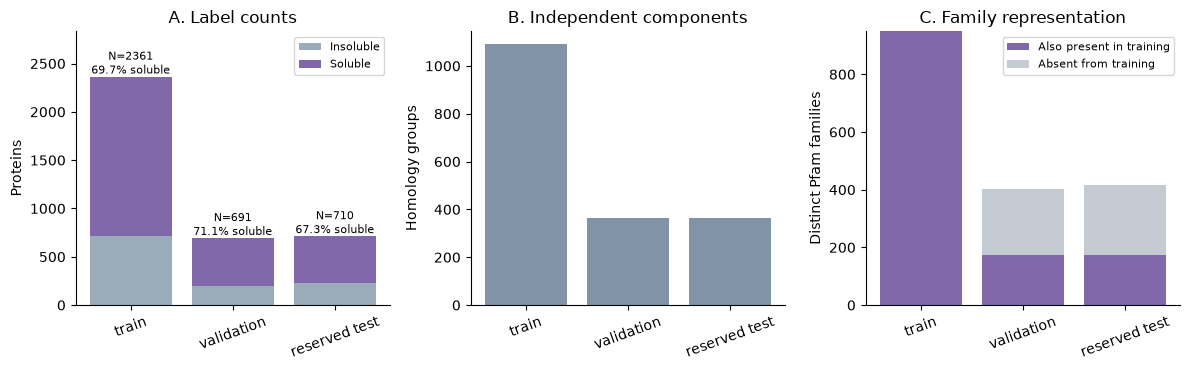

In [9]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3.8))
x = np.arange(len(splits))
names = splits.split.str.replace("_", " ")
axs[0].bar(x, splits.insoluble, color=COLORS[0], label="Insoluble")
axs[0].bar(x, splits.soluble, bottom=splits.insoluble, color=COLORS[1], label="Soluble")
for i, r in enumerate(splits.itertuples()):
    axs[0].text(
        i,
        r.N + 35,
        f"N={r.N}\n{r.percent_soluble:.1f}% soluble",
        ha="center",
        fontsize=8,
    )
axs[0].set(
    xticks=x,
    xticklabels=names,
    ylabel="Proteins",
    title="A. Label counts",
    ylim=(0, splits.N.max() * 1.2),
)
axs[0].legend(fontsize=8)
axs[1].bar(x, splits.groups, color="#8193a6")
axs[1].set(
    xticks=x,
    xticklabels=names,
    ylabel="Homology groups",
    title="B. Independent components",
)
fam = read(RESULTS / "initial_split_family_representation.tsv")
axs[2].bar(x, fam.shared_with_train, color="#8168aa", label="Also present in training")
axs[2].bar(
    x,
    fam.not_in_train,
    bottom=fam.shared_with_train,
    color="#c4cbd3",
    label="Absent from training",
)
axs[2].set(
    xticks=x,
    xticklabels=names,
    ylabel="Distinct Pfam families",
    title="C. Family representation",
)
axs[2].legend(fontsize=8)
for ax in axs:
    ax.tick_params(axis="x", rotation=20)
fig.tight_layout()
show(fig, "fig07_frozen_split_audit", FIGURES)

**Figure 7.** Whole homology components produce a test fraction near 20% and preserve both labels without forcing equal prevalence. Components cannot cross splits, but Pfam families can. This supports heterogeneous analysis and some within-family contrasts. Family-disjoint evaluation instead tests transfer to families absent from training (§5). Reruns use the saved split aggregates.

## 5. Within-family feasibility: training and validation

Select families with **≥3 or ≥5 training homology groups per class**, then report validation support at ≥1 and ≥3/≥5 groups per class. A mixed-label homology group can count in both classes; a separate sensitivity requires class-exclusive groups.

Compare all GA hits with removal of overlapping different-family hits within the same clan. This conservative uncertainty check is not official PfamScan adjudication and does not exclude proteins from the cohort. Same-E contrasts control the recorded expression stratum, not batch or construct identity.

,annotation_policy,training_groups_per_class,training_qualified_families,validation_both_families,validation_threshold_families,train_eligible_proteins,train_eligible_groups,validation_eligible_proteins,validation_eligible_groups,class_exclusive_training_qualified,class_exclusive_validation_both
0,all_GA,3,31,16,7,359,137,111,50,16,5
1,all_GA,5,13,8,2,228,99,80,36,7,2
2,no_competing_overlap,3,7,1,0,52,11,3,3,2,0
3,no_competing_overlap,5,1,0,0,0,0,0,0,0,0


,annotation_policy,threshold,pfam,name,train_g0,train_g1,validation_g0,validation_g1
0,all_GA,3,PF00004,AAA,6,6,1,3
1,all_GA,3,PF00535,Glycos_transf_2,5,24,5,9
2,all_GA,3,PF00890,FAD_binding_2,19,8,7,3
3,all_GA,3,PF01266,DAO,21,6,7,4
4,all_GA,3,PF01494,FAD_binding_3,13,6,6,3
5,all_GA,3,PF01593,Amino_oxidase,7,4,3,1
6,all_GA,3,PF01656,CbiA,5,3,2,3
7,all_GA,3,PF01844,HNH,5,3,1,3
8,all_GA,3,PF03364,Polyketide_cyc,4,4,1,1
9,all_GA,3,PF04055,Radical_SAM,11,4,1,2


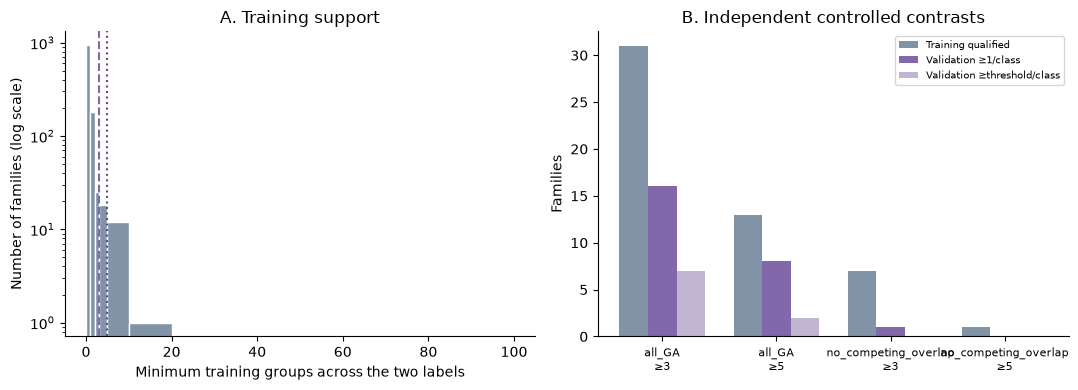

In [10]:
dev = development.copy()
dev.label = pd.to_numeric(dev.label).astype(int)
membercols = ["sha256", "pfam", "clan", "family_name", "description"]
variants = {
    "all_GA": development_domains,
    "no_competing_overlap": development_domains.loc[
        ~development_domains.competing_overlap
    ],
}
feasibility = []
supports = []
eligible_rows = []
for method, d in variants.items():
    mem = d[membercols].drop_duplicates(["sha256", "pfam"])
    f, x = support(dev, mem)
    f["annotation_policy"] = method
    supports.append(f)
    for k in [3, 5]:
        train_ok = (f.train_g0 >= k) & (f.train_g1 >= k)
        val_both = (f.validation_g0 >= 1) & (f.validation_g1 >= 1)
        val_strong = (f.validation_g0 >= k) & (f.validation_g1 >= k)
        eligible = set(f.loc[train_ok & val_both, "pfam"])
        eligible_rows += [
            dict(
                annotation_policy=method,
                threshold=k,
                pfam=r.pfam,
                name=r.name,
                train_g0=r.train_g0,
                train_g1=r.train_g1,
                validation_g0=r.validation_g0,
                validation_g1=r.validation_g1,
            )
            for r in f[train_ok & val_both].itertuples()
        ]
        counts = {
            "annotation_policy": method,
            "training_groups_per_class": k,
            "training_qualified_families": int(train_ok.sum()),
            "validation_both_families": int((train_ok & val_both).sum()),
            "validation_threshold_families": int((train_ok & val_strong).sum()),
        }
        for role in ["train", "validation"]:
            subset = x[(x.split == role) & x.pfam.isin(eligible)]
            counts[role + "_eligible_proteins"] = subset.record_id.nunique()
            counts[role + "_eligible_groups"] = subset.audit_cluster.nunique()
        # Strictly disjoint class groups measured within each partition.
        ex = []
        for role in ["train", "validation"]:
            z = dev[dev.split == role].assign(split=role)
            ef, _ = support(z, mem)
            ex.append(
                ef.set_index("pfam")[["exclusive_g0", "exclusive_g1"]].add_prefix(
                    role + "_"
                )
            )
        ex = ex[0].join(ex[1], how="left").fillna(0)
        counts["class_exclusive_training_qualified"] = int(
            ((ex.train_exclusive_g0 >= k) & (ex.train_exclusive_g1 >= k)).sum()
        )
        counts["class_exclusive_validation_both"] = int(
            (
                (ex.train_exclusive_g0 >= k)
                & (ex.train_exclusive_g1 >= k)
                & (ex.validation_exclusive_g0 >= 1)
                & (ex.validation_exclusive_g1 >= 1)
            ).sum()
        )
        feasibility.append(counts)
fs = pd.concat(supports, ignore_index=True)
feasibility = pd.DataFrame(feasibility)
save(fs, RESULTS / "development_family_support.tsv")
save(feasibility, RESULTS / "within_family_feasibility.tsv")
save(pd.DataFrame(eligible_rows), RESULTS / "controlled_family_candidates.tsv")
display(feasibility)
display(pd.DataFrame(eligible_rows).head(15))
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
a = fs[fs.annotation_policy == "all_GA"]
minimum = np.minimum(a.train_g0, a.train_g1)
axs[0].hist(
    minimum, bins=[0, 1, 2, 3, 5, 10, 20, 100], color="#8193a6", edgecolor="white"
)
axs[0].set_yscale("log")
axs[0].set(
    xlabel="Minimum training groups across the two labels",
    ylabel="Number of families (log scale)",
    title="A. Training support",
)
axs[0].axvline(3, color="#8168aa", ls="--")
axs[0].axvline(5, color="#644a8c", ls=":")
x = np.arange(len(feasibility))
w = 0.25
for delta, col, color, label in [
    (-w, "training_qualified_families", "#8193a6", "Training qualified"),
    (0, "validation_both_families", "#8168aa", "Validation ≥1/class"),
    (w, "validation_threshold_families", "#c2b5d4", "Validation ≥threshold/class"),
]:
    axs[1].bar(x + delta, feasibility[col], w, color=color, label=label)
axs[1].set(
    xticks=x,
    xticklabels=[
        f"{r.annotation_policy}\n≥{r.training_groups_per_class}"
        for r in feasibility.itertuples()
    ],
    ylabel="Families",
    title="B. Independent controlled contrasts",
)
axs[1].tick_params(axis="x", labelsize=8)
axs[1].legend(fontsize=7)
fig.tight_layout()
show(fig, "fig08_within_family_feasibility", FIGURES)

,E,training_groups_per_class,training_families,validation_both_families
0,4.0,3,6,4
1,4.0,5,2,2
2,5.0,3,23,12
3,5.0,5,10,6


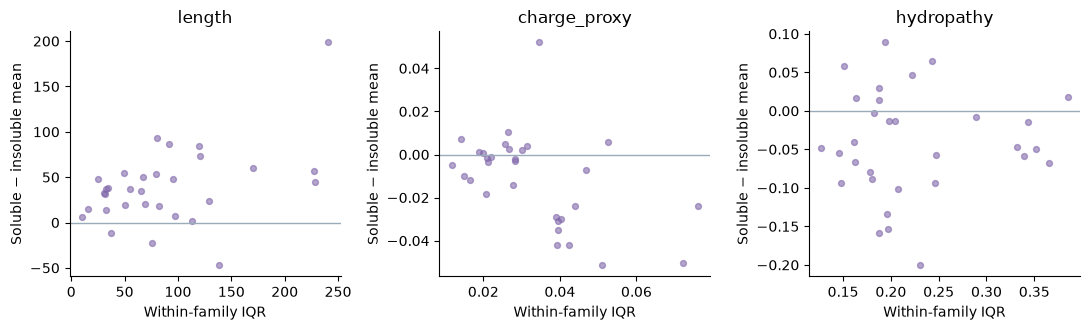

In [11]:
# Development-only same-E contrasts and within-family biochemical variation.
mem = variants["all_GA"][membercols].drop_duplicates(["sha256", "pfam"])
same_e = []
for e, q in dev.groupby("exp"):
    f, x = support(q, mem)
    for k in [3, 5]:
        qualified = (f.train_g0 >= k) & (f.train_g1 >= k)
        both = (f.validation_g0 >= 1) & (f.validation_g1 >= 1)
        same_e.append(
            dict(
                E=e,
                training_groups_per_class=k,
                training_families=int(qualified.sum()),
                validation_both_families=int((qualified & both).sum()),
            )
        )
save(pd.DataFrame(same_e), RESULTS / "same_E_family_contrasts.tsv")
display(pd.DataFrame(same_e))
train = dev[dev.split == "train"]
tx = train.merge(mem, on="sha256")
adequate = fs[
    (fs.annotation_policy == "all_GA") & (fs.train_g0 >= 3) & (fs.train_g1 >= 3)
].pfam
variation = []
for fam, g in tx[tx.pfam.isin(adequate)].groupby("pfam"):
    for feature in ["length", "charge_proxy", "hydropathy"]:
        vals = pd.to_numeric(g[feature], errors="coerce")
        means = g.assign(v=vals).groupby("label").v.mean()
        variation.append(
            dict(
                pfam=fam,
                name=g.family_name.iloc[0],
                feature=feature,
                N=len(g),
                IQR=vals.quantile(0.75) - vals.quantile(0.25),
                mean_difference_soluble_minus_insoluble=means.get(1, np.nan)
                - means.get(0, np.nan),
            )
        )
variation = pd.DataFrame(variation)
save(variation, RESULTS / "training_within_family_biochemistry.tsv")
fig, axs = plt.subplots(1, 3, figsize=(11, 3.4))
for ax, feature in zip(axs, ["length", "charge_proxy", "hydropathy"]):
    z = variation[variation.feature == feature]
    ax.scatter(
        z.IQR,
        z.mean_difference_soluble_minus_insoluble,
        color="#8168aa",
        s=18,
        alpha=0.6,
    )
    ax.axhline(0, color="#9aabba", lw=1)
    ax.set(title=feature, xlabel="Within-family IQR", ylabel="Soluble − insoluble mean")
fig.tight_layout()
show(fig, "fig09_training_family_biochemistry", FIGURES)

**Figures 8–9.** Eligible-protein counts deduplicate across families. One validation group per class establishes minimal support, not adequate statistical power. Shared Pfam membership also leaves biochemical, architecture and organism variation. Same-E comparisons control only the recorded expression stratum.

At ≥3/≥5 training groups per class, **16/8 families** have both validation labels using all GA hits; overlap removal leaves **1/0**. The remaining Radical SAM family (PF04055) has three validation proteins and fails the stricter class-exclusive-group sensitivity. Broad confirmatory within-family analysis needs further annotation and architecture validation.

,training_N,family_components,largest_component_N,largest_component_percent,unannotated,folds_with_both_labels
0,2361,695,153,6.480305,156,5


,family_cv_fold,N,soluble,homology_groups,annotated,insoluble,annotated_insoluble,annotated_soluble,heldout_families
0,0,312,224,167,285,88,79,206,166
1,1,616,424,259,587,192,177,410,241
2,2,390,299,189,364,91,76,288,170
3,3,295,219,148,262,76,55,207,129
4,4,748,479,327,707,269,252,455,243


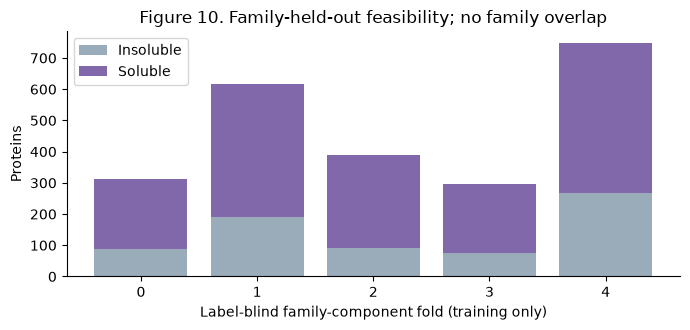

In [12]:
# Separate family-held-out feasibility experiment on TRAINING ONLY.
# Join existing homology groups AND all proteins sharing any GA-passing Pfam.
# This handles multidomain bridges; representative-family-only splitting would leak families.
training = dev[dev.split == "train"].copy()
tm = training[["sha256", "audit_cluster"]].merge(mem, on="sha256")
links = []
for _, g in training.groupby("audit_cluster"):
    ids = g.sha256.tolist()
    links += [(ids[0], s) for s in ids[1:]]
for _, g in tm.groupby("pfam"):
    ids = g.sha256.drop_duplicates().tolist()
    links += [(ids[0], s) for s in ids[1:]]
components = component_ids(training.sha256, links)
training["family_component"] = training.sha256.map(components)
training["family_cv_fold"] = training.family_component.map(
    lambda s: int(seqhash("nesg-family-heldout-v1:" + s)[:16], 16) % 5
)
linked = training[["sha256", "family_cv_fold"]].merge(mem, on="sha256")
assert linked.groupby("pfam").family_cv_fold.nunique().max() == 1
assert training.groupby("audit_cluster").family_cv_fold.nunique().max() == 1
annotated = set(tm.sha256)
training["family_annotated"] = training.sha256.isin(annotated)
fho = (
    training.groupby("family_cv_fold")
    .agg(
        N=("label", "size"),
        soluble=("label", "sum"),
        homology_groups=("audit_cluster", "nunique"),
        annotated=("family_annotated", "sum"),
    )
    .reset_index()
)
fho["insoluble"] = fho.N - fho.soluble
for lab, col in [(0, "annotated_insoluble"), (1, "annotated_soluble")]:
    counts = (
        training[training.family_annotated & (training.label == lab)]
        .groupby("family_cv_fold")
        .size()
    )
    fho[col] = fho.family_cv_fold.map(counts).fillna(0).astype(int)
fho["heldout_families"] = (
    fho.family_cv_fold.map(linked.groupby("family_cv_fold").pfam.nunique())
    .fillna(0)
    .astype(int)
)
assert (fho[["annotated_insoluble", "annotated_soluble"]] > 0).all().all()
size = training.groupby("family_component").size().sort_values(ascending=False)
fh_summary = pd.DataFrame(
    [
        dict(
            training_N=len(training),
            family_components=len(size),
            largest_component_N=int(size.max()),
            largest_component_percent=100 * size.max() / len(training),
            unannotated=int((~training.family_annotated).sum()),
            folds_with_both_labels=int(((fho.soluble > 0) & (fho.insoluble > 0)).sum()),
        )
    ]
)
save(
    training[
        [
            "record_id",
            "sha256",
            "audit_cluster",
            "family_component",
            "family_cv_fold",
            "family_annotated",
        ]
    ],
    RESULTS / "training_family_heldout_feasibility_manifest.tsv",
)
save(fho, RESULTS / "training_family_heldout_counts.tsv")
save(fh_summary, RESULTS / "training_family_heldout_summary.tsv")
display(fh_summary)
display(fho)
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.bar(fho.family_cv_fold, fho.insoluble, color=COLORS[0], label="Insoluble")
ax.bar(
    fho.family_cv_fold,
    fho.soluble,
    bottom=fho.insoluble,
    color=COLORS[1],
    label="Soluble",
)
ax.set(
    xlabel="Label-blind family-component fold (training only)",
    ylabel="Proteins",
    title="Figure 10. Family-held-out feasibility; no family overlap",
)
ax.legend()
fig.tight_layout()
show(fig, "fig10_family_heldout_feasibility", FIGURES)

**Figure 10.** These separate training-only folds join proteins through every assigned family and homology group, including multidomain bridges. Large components can make folds unequal. Proteins without Pfam hits remain included but cannot establish transfer to a known unseen family. Shared clans and remote relationships may persist. Neither validation nor test is used to construct these folds.

## 6. Final dataset assessment

**Ready with limitations for heterogeneous ESM analysis.** The phenotype is recombinant soluble recovery conditional on high expression in the NESG setting. Record-level assay matching and universal thermodynamic solubility are not established.

Heterogeneous analysis A retains the frozen cohort and natural family–label associations. Controlled analysis B has 16/8 minimally supported families at the ≥3/≥5 training-group thresholds, falling to 1/0 under overlap sensitivity. Validate competing assignments and full-protein architectures before confirmatory within-family claims. Family-held-out evaluation is a separate generalization experiment.

Next, extract frozen ESM-2 activations for training/validation with explicit handling of X. Tune probes using training-only group CV. Specify feature selection, readouts and intervention controls before SAE experiments. The test's later family-label inspection is disclosed above; these descriptive results must not guide model selection.

In [13]:
# Development-only consistency checks and provenance. No reserved-test rows are opened.
assert dev.record_id.is_unique and dev.sha256.is_unique
assert (dev.sequence.map(seqhash) == dev.sha256).all()
assert dev.exp.isin([4, 5]).all() and dev.sol.isin([0, 4, 5]).all()
assert (dev.label == (dev.sol >= 4).astype(int)).all()
assert dev.groupby("audit_cluster").split.nunique().max() == 1
assert (
    dev[dev.split == "train"].groupby("audit_cluster").inner_cv_fold.nunique().max()
    == 1
)
assert set(development_domains.sha256) <= set(dev.sha256)
assert (RESULTS / "test_lock.json").exists()
verify_frozen_snapshot(RESULTS)
versions = {
    name: importlib.metadata.version(name)
    for name in [
        "numpy",
        "pandas",
        "matplotlib",
        "nbformat",
        "nbclient",
        "ipykernel",
        "jupyter_client",
    ]
}
provenance = dict(
    python=sys.version,
    platform=platform.platform(),
    packages=versions,
    mode="locked_rerun"
    if (RESULTS / "execution_provenance.json").exists()
    else "initial_execution",
    test_lock_status="LOCKED",
    models_trained=False,
    annotations_recomputed=False,
    UESolDS_independent_test_accessed=False,
)
(RESULTS / "execution_provenance.json").write_text(
    json.dumps(provenance, indent=2) + "\n"
)
checks = json.loads((RESULTS / "integrity_checks.json").read_text())
checks["development_only_final_checks"] = "PASS"
checks["frozen_snapshot_hashes"] = "PASS"
checks["family_heldout_shared_accessions"] = 0
(RESULTS / "final_validation.json").write_text(json.dumps(checks, indent=2) + "\n")
display(pd.DataFrame([checks]))
md(
    "**Final cohort:** 3,762 proteins; 2,614 soluble and 1,148 insoluble. **Reserved test remains locked.**"
)
display(
    feasibility[
        [
            "annotation_policy",
            "training_groups_per_class",
            "training_qualified_families",
            "validation_both_families",
            "train_eligible_proteins",
            "validation_eligible_proteins",
        ]
    ]
)
print("Dependency versions:", versions)
(RESULTS / "notebook_project_file_access.json").write_text(
    json.dumps(guard.accesses, indent=2) + "\n"
)

,cohort_records,unique_sequences,soluble,insoluble,exact_cross_split_sequences,cross_split_groups,cohort_direct_edges,cross_split_detected_edges,all_union_edges_verified,training_cv_group_leakage,original_strict_membership_and_scores_unchanged,development_only_final_checks,frozen_snapshot_hashes,family_heldout_shared_accessions
0,3762,3762,2614,1148,0,0,15196,0,447527,0,True,PASS,PASS,0


**Final cohort:** 3,762 proteins; 2,614 soluble and 1,148 insoluble. **Reserved test remains locked.**

,annotation_policy,training_groups_per_class,training_qualified_families,validation_both_families,train_eligible_proteins,validation_eligible_proteins
0,all_GA,3,31,16,359,111
1,all_GA,5,13,8,228,80
2,no_competing_overlap,3,7,1,52,3
3,no_competing_overlap,5,1,0,0,0


Dependency versions: {'numpy': '2.5.1', 'pandas': '2.3.3', 'matplotlib': '3.11.1', 'nbformat': '5.10.4', 'nbclient': '0.10.2', 'ipykernel': '7.3.0', 'jupyter_client': '8.10.0'}


6657